# 24 · Inspect agreement on a digit retrieval error

Take a held-out query where the fixed uniform profile fails same-digit retrieval and the development-selected class comparator succeeds. Reconstruct the exact query and inspect how the named agreements favor its two competing matches.

In the inspected blurred 7 example, local Q favors the other 7, while fourth angular order and DCT power favor a 6 strongly enough to determine the uniform-profile decision.

In [1]:
from pathlib import Path
import sys, json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.open_images import COMPONENTS,Observation,translate,describe,open_moment,similarity_profile
from observables.stage6 import CONDITIONS,SEED,load_data,galleries,view,run,paired_interval
OUT=ROOT/'results'/'stage6'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

In [3]:
if not (OUT/'pair_distances.csv.gz').exists():
    run(OUT)
decisions=pd.read_csv(OUT/'decisions.csv.gz')
pairs=pd.read_csv(OUT/'pair_distances.csv.gz')
manifest=json.loads((OUT/'manifest.json').read_text())
best=manifest['development_selected']['class']
membership=pd.read_csv(OUT/'gallery_membership.csv')
keys=['split','gallery','source','condition']
test=decisions.query("split=='test' and condition!='clean'").pivot(index=keys,columns='method',values='class')
cases=test[(test['uniform profile']==0)&(test[best]==1)]
key=cases.index[0]
group=pairs.set_index(keys).loc[[key]]
group=group[group.candidate!=key[2]]
gallery=membership[(membership.split=='test')&(membership.gallery==key[1])].set_index('source')
truth=int(group.candidate[group.candidate.map(gallery.label)==gallery.loc[key[2],'label']].iloc[0])
winner=int(group.candidate.iloc[group[list(COMPONENTS)].mean(1).argmin()])
assert winner!=truth
print('Query:',key,'· correct candidate:',truth,'· uniform winner:',winner,'· comparator:',best)

Query: ('test', 0, 171, 'blur') · correct candidate: 3400 · uniform winner: 8739 · comparator: local Q


## Reconstruct the observed evidence
The deterministic generator recreates every perturbation in the original order. The candidate's known class labels are used to interpret the scorecard after the decision. A blue region indicates pixels outside the observed support.

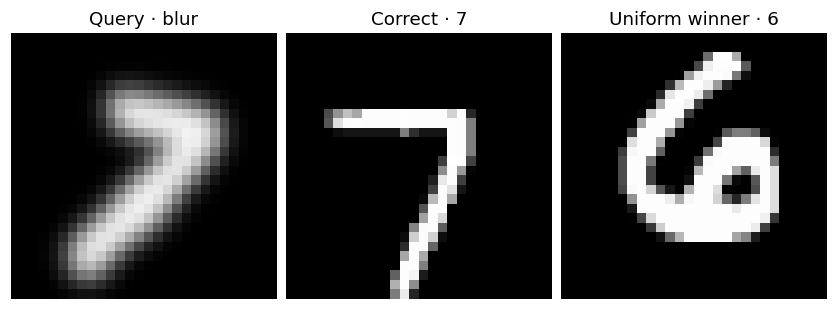

In [5]:
data=load_data()
rng=np.random.default_rng(SEED+1)
query=None
for split,block,ids,images,labels in galleries(data):
    for source,image in zip(ids,images):
        for condition in CONDITIONS:
            candidate_view=view(image,condition,rng)
            if (split,block,source,condition)==key:
                query=candidate_view
    if query is not None:
        break
assert query is not None
fig,axes=plt.subplots(1,3,figsize=(7.5,2.8))
cmap=plt.get_cmap('gray').with_extremes(bad='#9ac7e7')
for ax,image,title in zip(axes,[np.where(query.valid,query.image,np.nan),
                              data['x_test'][truth]/255,data['x_test'][winner]/255],
                         [f'Query · {key[-1]}',f'Correct · {gallery.loc[truth,"label"]}',
                          f'Uniform winner · {gallery.loc[winner,"label"]}']):
    ax.imshow(image,cmap=cmap,vmin=0,vmax=1);ax.set_title(title);ax.set_axis_off()
show('24_mnist_error')

## Recover the exact decision gap
For each coordinate, report $S_j(A,B_{winner})-S_j(A,B_{true})$. Positive values favor the uniform winner. Divide by 11 to obtain the contribution to the uniform score gap. Candidate-level offsets and coverage are retained because individual aligned terms can use different regions.

,correct agreement,winner agreement,winner minus correct,uniform contribution
pixels,0.50742,0.52173,0.01430,0.00130
polar m1,0.00000,0.00000,-0.00000,-0.00000
global Q,0.86112,0.88770,0.02658,0.00242
angular m4,0.15675,0.56589,0.40914,0.03719
HOG,0.33238,0.39393,0.06154,0.00559
local Q,0.46392,0.27141,-0.19251,-0.01750
open Q pairs,0.93711,0.93303,-0.00409,-0.00037
open Q triplets,0.56329,0.52719,-0.03610,-0.00328
DCT power,0.49542,0.71052,0.21510,0.01955
aligned pixels,0.53506,0.52173,-0.01333,-0.00121


,pixel_dy,pixel_dx,Q_dy,Q_dx,pixel_coverage,Q_coverage
candidate,,,,,,
3400,1,1,2,-3,0.929847,0.829082
8739,0,0,3,3,1.000000,0.797194


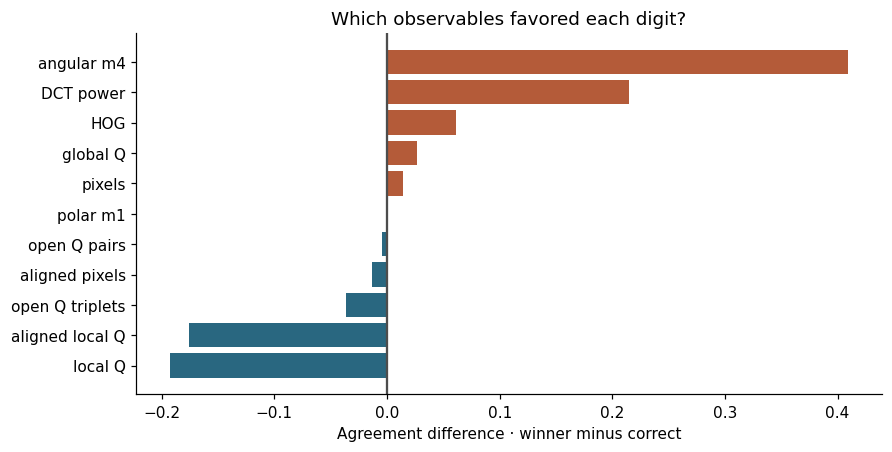

In [7]:
g=group.set_index('candidate')
w=g.loc[winner,list(COMPONENTS)].astype(float)
t=g.loc[truth,list(COMPONENTS)].astype(float)
card=pd.DataFrame({'correct agreement':1-t,'winner agreement':1-w,
                   'winner minus correct':t-w,'uniform contribution':(t-w)/len(COMPONENTS)})
np.testing.assert_allclose(card['uniform contribution'].sum(),t.mean()-w.mean())
assert card['uniform contribution'].sum()>0
display(card.round(5));card.to_csv(OUT/'mnist_failure_scorecard.csv')
display(g.loc[[truth,winner],['pixel_dy','pixel_dx','Q_dy','Q_dx','pixel_coverage','Q_coverage']])
delta=card['winner minus correct'].sort_values()
fig,ax=plt.subplots(figsize=(8,4))
ax.barh(delta.index,delta,color=np.where(delta>0,'#b45b39','#296780'))
ax.axvline(0,color='.3');ax.set(xlabel='Agreement difference · winner minus correct',
                              title='Which observables favored each digit?')
show('24_mnist_attribution')

This example illustrates how to use the profile on a standard image. The scorecard explains the numerical outcome for an observed pair of candidates. It does not establish which one a person would find visually more similar. The label supplies a defined recognition target.